# GTX-A 연구 대상지 위치도와 권역별 확대 지도

하루 전체 광역버스 승차 변화(2025년 − 2024년)를 실제 250m 분석 격자에 표시합니다. **GTX-A는 세 역의 위치만 표시합니다.**

- 운정중앙역 63개 · 킨텍스역 26개 · 대곡역 37개, 총 126개
- 감소: 빨강 · 유지: 연회색 · 증가: 파랑
- 운정중앙·대곡은 좌우 확대 지도, 가운데는 파주·고양 위치도와 킨텍스 확대 지도
- 전체 격자가 각 확대 지도에 포함됩니다. 일부 격자를 숨기거나 TOP 3를 강조하지 않습니다.

`S1_126격자_건수기준_기초표.csv`의 `board_2024`, `board_2025`, `change`, `nearest_station`과 원본 250m SHP를 사용합니다. 격자 ID 생성 순서는 기존 011과 같고, 중심점 좌표도 대조합니다. 행정경계와 역사 좌표는 기존 프로젝트 자료를 사용합니다. 행정경계는 2026년 지도 맥락 자료로, 2024년 당시 경계를 뜻하지 않습니다.

그림 파일은 저장하지 않습니다. 실제 회색 배경지도는 실행 후 브라우저에서 CARTO/OSM 타일을 불러옵니다. 인터넷 연결이 필요하며 API 키는 필요하지 않습니다. 타일은 지도 배경일 뿐 2024/2025년 도로·시설 변화를 입증하는 자료가 아닙니다.

In [1]:
from pathlib import Path
import importlib.util
from IPython.display import display

map_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'config.py').is_file() and (p / 'code').is_dir())
map_spec = importlib.util.spec_from_file_location('study_area_015', map_root / 'code/03_eda/study_area_015.py')
map_015 = importlib.util.module_from_spec(map_spec)
map_spec.loader.exec_module(map_015)
map_grid, map_stations, map_cities, map_summary = map_015.load_data(map_root)
display(map_summary)
print('126개 실제 격자 · 중심점 좌표 일치 · 변화량 = 개통 후 − 개통 전 검증 완료')

,격자수,개통전,개통후,변화량,감소,유지,증가
nearest_station,,,,,,,
운정중앙,63,2568,1896,-672,39,6,18
킨텍스,26,3492,2617,-875,20,1,5
대곡,37,1050,1004,-46,17,8,12
전체,126,7110,5517,-1593,76,15,35


126개 실제 격자 · 중심점 좌표 일치 · 변화량 = 개통 후 − 개통 전 검증 완료


In [ ]:
# 이 셀은 지도 파일을 저장하지 않습니다.
# PNG 보기 / SVG 보기로 전환할 수 있습니다. PNG는 우클릭하여 복사하세요.
import matplotlib.pyplot as plt

study_fig, study_axes, study_bounds = map_015.make_figure(map_grid, map_stations, map_cities)
study_page = map_015.browser_page(study_fig, study_axes, study_bounds, dpi=300)
study_url = map_015.show_browser_map(study_page, height=830)
plt.close(study_fig)
print('브라우저에서 크게 보기:', study_url)
print('PNG 6300 × 3600 · SVG 벡터 격자/글자 + 배경지도 타일 · 자동 저장 없음')

## 카카오맵 캡처를 넣은 연구 대상지 그림

중앙에는 실제 파주·고양 행정경계와 분석 격자 126개를 표시하고, 주변 확대 지도에는 제공한 **운정중앙 카맵.png · 킨텍스 카맵.png · 대곡역 카맵.png**를 그대로 사용합니다. 사진의 비율, 전체 화면, 카카오 출처와 축척을 유지합니다.

확대 사진은 각 권역의 **일부 지역**을 보여줍니다. 사진 속 실제 격자와 GIS 격자의 위치를 대조하여 중앙 지도의 캡처 범위를 추정합니다. 청록색 강조선이 들어간 최신 캡처를 사용하며, 대조에 사용하는 격자 중심점의 최대 위치 오차가 2.5 px 이내인지 실행 시 확인합니다.

아래 셀 하나로 출력할 수 있습니다. 인터넷이나 API 키가 필요하지 않으며, 합성 그림 파일을 따로 저장하지 않습니다.

**밝은 청록색 테두리**는 하루 전체 변화량이 −40건 이하인 격자(운정중앙 6개·킨텍스 5개·대곡 0개)를 뜻합니다. 사진에 표시된 강조선을 그대로 유지합니다.

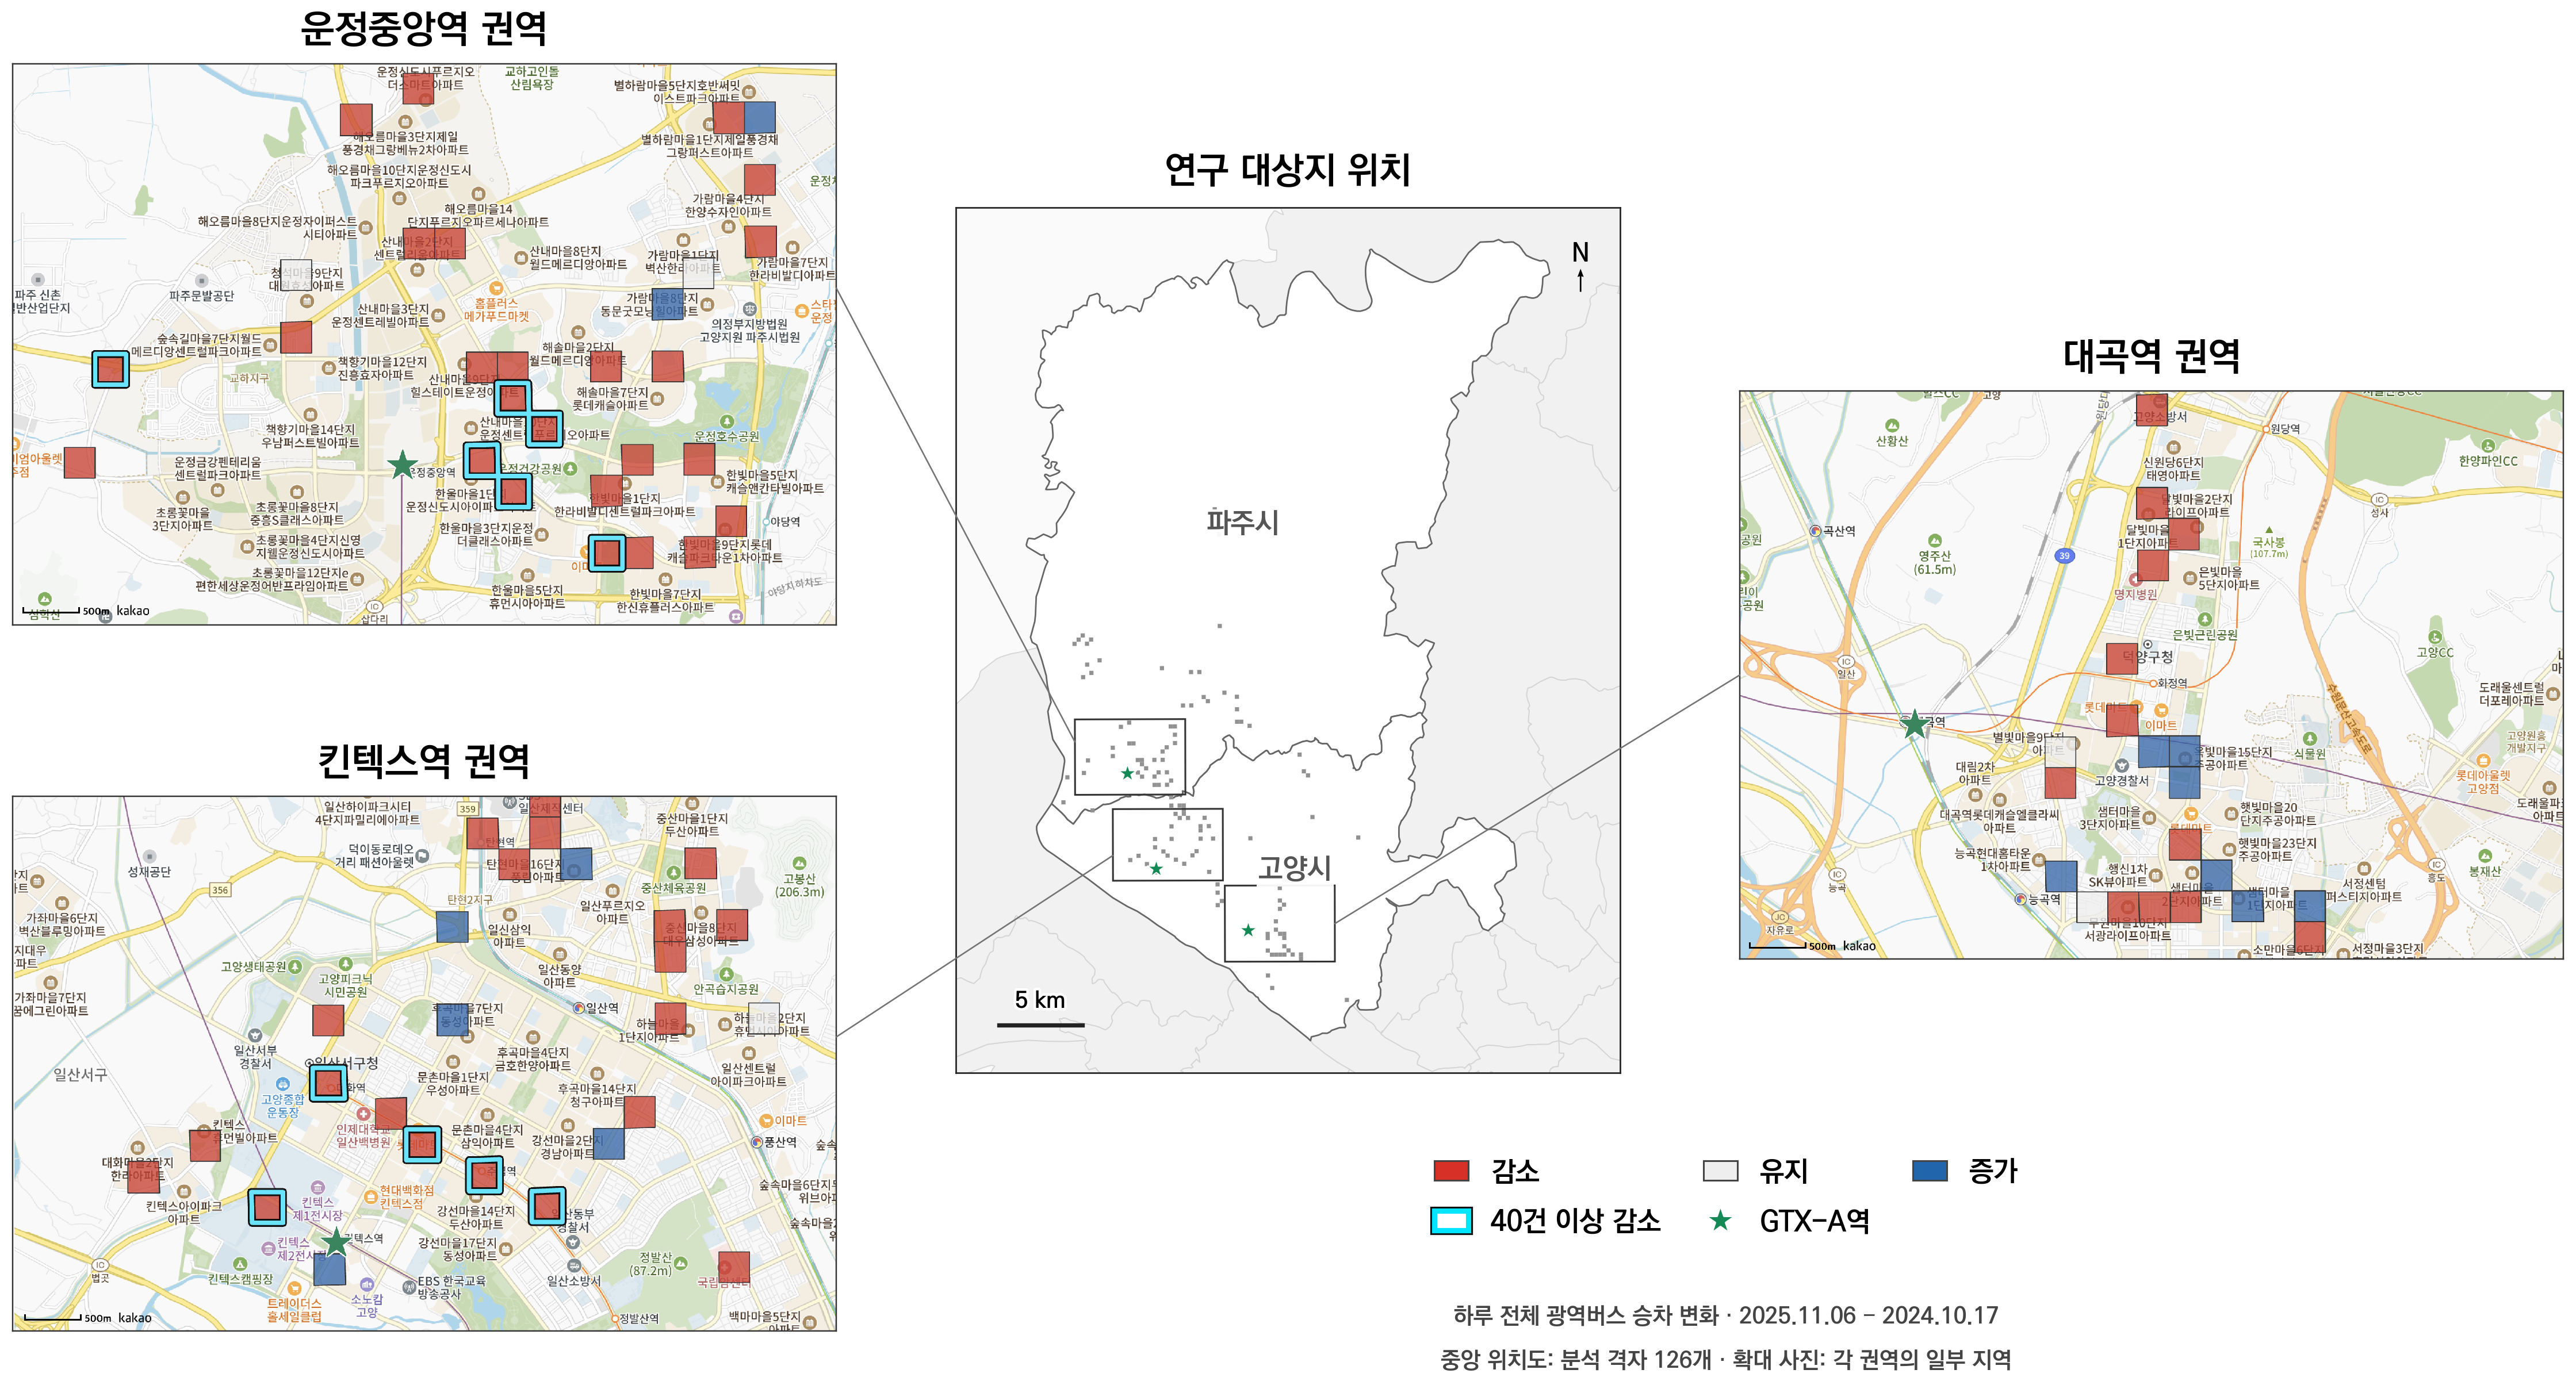

In [1]:
# 제공된 카카오맵 3장을 확대 사진으로 사용합니다. 파일 자동 저장 없음.
from pathlib import Path
import importlib.util
import matplotlib.pyplot as plt
from IPython.display import Image, display
import io

map_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'config.py').is_file() and (p / 'code').is_dir())
capture_layout_spec = importlib.util.spec_from_file_location(
    'study_area_capture_015', map_root / 'code/03_eda/study_area_015.py')
map_015 = importlib.util.module_from_spec(capture_layout_spec)
capture_layout_spec.loader.exec_module(map_015)
map_grid, map_stations, map_cities, map_summary = map_015.load_data(map_root)

layout_fig, layout_axes, capture_validation = map_015.make_capture_figure(
    map_grid, map_stations, map_cities, map_root)
layout_buffer = io.BytesIO()
layout_fig.savefig(layout_buffer, format='png', dpi=220, facecolor='white', bbox_inches='tight')
plt.close(layout_fig)
display(Image(data=layout_buffer.getvalue()))

## 하루 전체 순위상관 산점도 — 두 하차 정류장 제외

`양우아파트.대곡역롯데캐슬`(4111411) 22건과 `대곡역롯데캐슬엘클라씨`(4111412) 4건을 제외한 결과입니다. 원자료와 기존 분석표를 덮어쓰지 않고, 2025년 원본 승차기록에서 다시 집계합니다.

- 분석 격자는 **126개 그대로** 유지합니다. 0건인 85개 격자도 포함합니다.
- 제외 후 **989건 · 승차가 있는 격자 41개 · 중복 제외 21개 노선**입니다. 권역은 승차 격자의 최근접 GTX역을 기준으로 합니다.
- X축은 개통 후 − 개통 전 광역버스 승차건수, Y축은 제외 후 개통 후 GTX역 연계버스 승차건수입니다.
- X축은 각 권역의 전체 자료를 포함하고, Y축은 세 권역 모두 동일합니다. 이상치를 제거하거나 점을 잘라내지 않습니다.
- 겹친 점을 보이게 하려고 표시 위치만 조금 옮깁니다. 상관계수와 양측 p값은 위치를 옮기기 전 실제 값으로 계산하며, 선형회귀선은 추가하지 않습니다.
- 아래 두 셀만 실행해도 됩니다. 지도 실행·인터넷·카카오 키는 필요하지 않습니다. 이미지 파일을 저장하지 않습니다.

In [3]:
from pathlib import Path
import importlib.util
from IPython.display import display

scatter_root_015 = next(p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'config.py').is_file() and (p / 'code').is_dir())
scatter_spec_015 = importlib.util.spec_from_file_location(
    'feeder_scatter_015', scatter_root_015 / 'code/03_eda/feeder_scatter_015.py')
scatter_module_015 = importlib.util.module_from_spec(scatter_spec_015)
scatter_spec_015.loader.exec_module(scatter_module_015)
scatter_data_015, scatter_stats_015, excluded_records_015 = scatter_module_015.load_corrected(scatter_root_015)

scatter_table_015 = scatter_stats_015.rename(columns={'rho': 'Spearman ρ', 'p': 'p-value'}).copy()
scatter_table_015['Spearman ρ'] = scatter_table_015['Spearman ρ'].map(lambda v: f'{v:.3f}')
scatter_table_015['p-value'] = scatter_table_015['p-value'].map(lambda v: '< .001' if v < .001 else f'{v:.3f}')
display(scatter_table_015)
print('제외 26건 · 총 989건 · 승차가 있는 격자 41개 · 0건 85개 · 중복 제외 21개 노선')
print('기존 126개 격자 유지 · 원자료와 기존 분석표 변경 없음')

,분석 격자,승차가 있는 격자,승차건수,노선 수,Spearman ρ,p-value
권역,,,,,,
운정중앙,63,21,672,9,-0.410,< .001
킨텍스,26,8,109,12,-0.199,0.330
대곡,37,12,208,4,-0.485,0.002
전체,126,41,989,21,-0.343,< .001


제외 26건 · 총989건 · 승차가 있는 격자41개 · 0건85개 · 중복 제외21개 노선


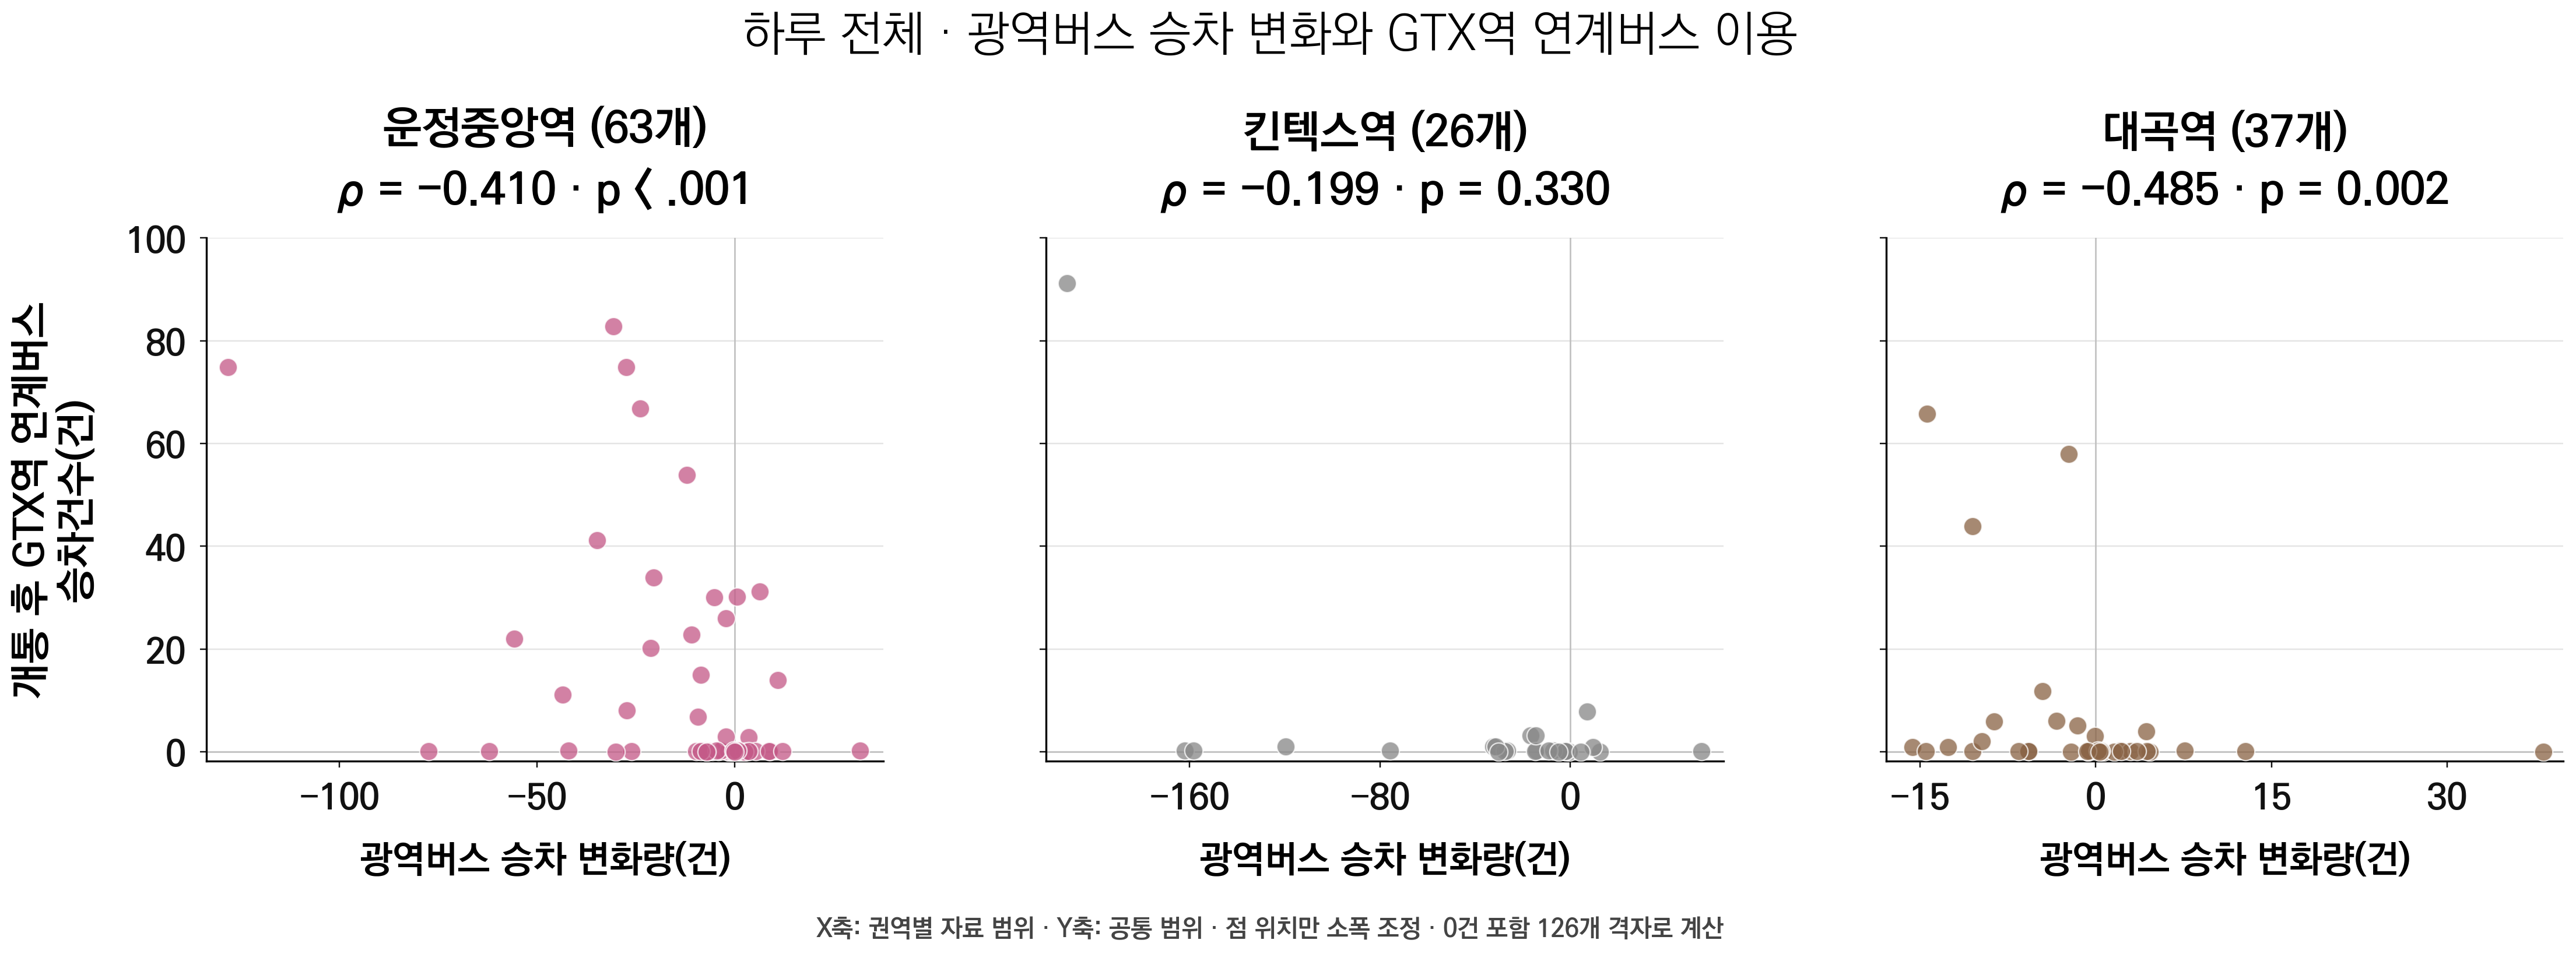

In [4]:
# 권역별 지터 산점도. 이미지 파일은 저장하지 않습니다.
import matplotlib.pyplot as plt
from IPython.display import Image, display
import io

scatter_fig_015 = scatter_module_015.make_scatter(scatter_data_015, scatter_stats_015)
scatter_image_015 = io.BytesIO()
scatter_fig_015.savefig(scatter_image_015, format='png', dpi=220, facecolor='white', bbox_inches='tight')
plt.close(scatter_fig_015)
display(Image(data=scatter_image_015.getvalue()))

## 권역별 하루 전체 카카오맵 — 스크린샷용

기존 011과 동일한 **하루 전체 광역버스 승차 변화량**을 실제 250m 격자에 표시합니다. 감소는 빨강, 유지는 연회색, 증가는 파랑이며 GTX역 위치는 초록 별로 표시합니다. 연계버스 989건 비교 산점도와는 별개의 지도입니다.

- 운정중앙역 63개 · 킨텍스역 26개 · 대곡역 37개, 총 126개
- **밝은 청록색 이중 테두리:** 변화량이 **−40건 이하**인 격자만 강조합니다. 운정중앙 6개 · 킨텍스 5개 · 대곡 0개, 총 11개입니다.
- 처음에는 해당 권역의 전체 격자가 나옵니다. `주요지역 확대`를 누르면 일부 지역을 크게 볼 수 있습니다. 확대해도 화면 밖 격자를 삭제하지 않습니다.
- 오른쪽 위 작은 전체 지도, TOP 3 강조, 노선선, 추가 시설 경계는 넣지 않았습니다.
- 각 지도 위 **새 탭에서 크게 열기 · 스크린샷** 링크를 사용하세요. 새 탭에서 지도를 움직이고 확대할 수 있습니다.
- **C** 또는 **지도만 보기** 버튼으로 제목·버튼·범례를 숨기고 캡처합니다. 다시 C를 누르면 복원됩니다. 카카오 출처 표시는 유지됩니다.
- 아래 셀 하나만 실행해도 됩니다. **카카오 JavaScript 키**를 입력하세요. 키는 코드나 출력에 기록하지 않습니다. 기본 주소는 `http://localhost:8765`이며, 사용 중이면 빈 포트로 자동 전환합니다. 지도 연결 오류가 나면 출력된 주소를 카카오 앱 → 플랫폼 키 → 해당 JavaScript 키 → **JavaScript SDK 도메인**에 추가하세요. 기본적으로 `http://localhost:8765`와 `http://localhost:8766`을 등록하면 현재 두 포트를 모두 사용할 수 있습니다.
- HTML·PNG·SVG·스크린샷은 자동 저장하지 않습니다.

In [8]:
# 권역별 하루 전체 카카오맵: 이 셀만 실행 → 키 입력 → 새 탭에서 캡처
from pathlib import Path
import importlib.util
import os
import getpass
from IPython.display import display

kakao_root_015 = next(p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / 'config.py').is_file() and (p / 'code').is_dir())
kakao_spec_015 = importlib.util.spec_from_file_location(
    'kakao_day_capture_015', kakao_root_015 / 'code/03_eda/kakao_day_capture_015.py')
kakao_module_015 = importlib.util.module_from_spec(kakao_spec_015)
kakao_spec_015.loader.exec_module(kakao_module_015)
kakao_grid_015, kakao_stations_015, kakao_summary_015 = kakao_module_015.load_map_data(kakao_root_015)
display(kakao_summary_015)
print('밝은 청록색 테두리: 변화량 ≤ −40건 · 운정중앙 6 / 킨텍스 5 / 대곡 0 · 총 11개')

kakao_key_015 = os.getenv('KAKAO_JAVASCRIPT_KEY', '').strip() or getpass.getpass('카카오 JavaScript 키: ').strip()
try:
    kakao_links_015 = kakao_module_015.show_maps(
        kakao_grid_015, kakao_stations_015, kakao_root_015, kakao_key_015)
finally:
    del kakao_key_015
print('각 지도 위 새 탭 링크 → 전체 보기/주요지역 확대 → C로 지도만 표시 → 직접 캡처')

,격자수,개통전,개통후,변화량,감소,유지,증가
nearest_station,,,,,,,
운정중앙,63,2568,1896,-672,39,6,18
킨텍스,26,3492,2617,-875,20,1,5
대곡,37,1050,1004,-46,17,8,12
전체,126,7110,5517,-1593,76,15,35


밝은 청록색 테두리: 변화량 ≤ −40건 · 운정중앙 6 / 킨텍스 5 / 대곡 0 · 총 11개


각 지도 위 새 탭 링크 → 전체 보기/주요지역 확대 → C로 지도만 표시 → 직접 캡처


## 순위 산점도 설명용 예시 — A·B·C

전체 자료에서 부여한 순위 중 세 격자를 골라 보여주는 예시로 구성합니다. 기존 126개 격자의 실제 분석 결과와는 별개입니다.

| 격자 | 광역버스 승차 변화량 순위 | 연계버스 승차건수 순위 |
|---|---|---|
| A | 1위 (−120건) | 4위 (60건) |
| B | 2위 (−40건) | 3위 (25건) |
| C | 3위 (−10건) | 1위 (5건) |

각 점은 격자 하나이며, X축은 광역버스 변화량 순위, Y축은 연계버스 승차건수 순위입니다. 좌표는 **A(1,4), B(2,3), C(3,1)**입니다. 전체 순위 중 일부를 보여주는 가정이므로 표시된 세 점만으로 전체 자료의 상관계수를 제시하지 않습니다.

이전 예시 산점도를 이 그림으로 교체합니다. 아래 셀만 실행할 수 있으며 이미지 파일을 따로 저장하지 않습니다.

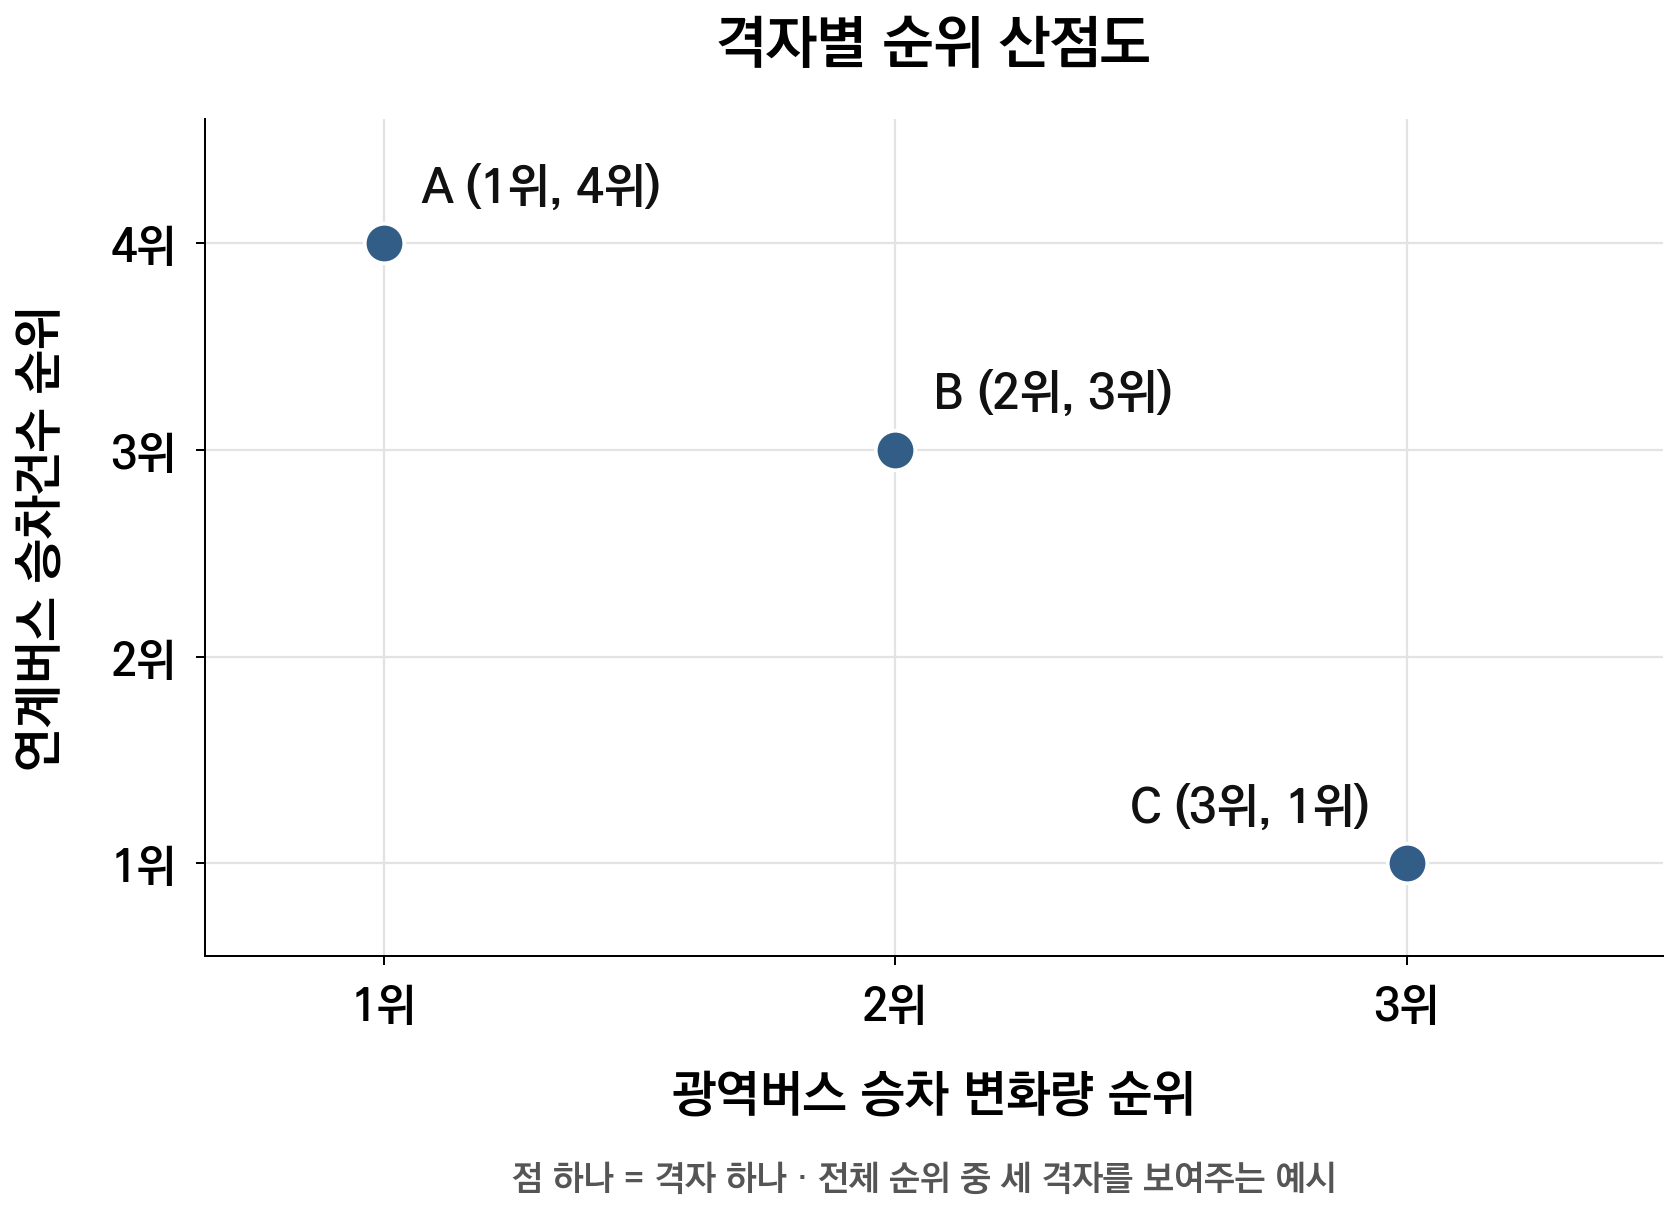

In [1]:
# 순위 예시: A(1,4), B(2,3), C(3,1)
from pathlib import Path
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import Image, display

example_rank_015 = pd.DataFrame({
    '격자': ['A', 'B', 'C'],
    '광역버스 승차 변화량(건)': [-120, -40, -10],
    '연계버스 승차건수(건)': [60, 25, 5],
    '광역버스 순위': [1, 2, 3],
    '연계버스 순위': [4, 3, 1],
})
example_font_015 = 'DejaVu Sans'
for font_path in [Path.home() / 'Library/Fonts/KoPubWorld Dotum Bold.ttf',
                  Path('/System/Library/Fonts/AppleSDGothicNeo.ttc'),
                  Path('C:/Windows/Fonts/malgunbd.ttf')]:
    if font_path.is_file():
        fm.fontManager.addfont(str(font_path))
        example_font_015 = fm.FontProperties(fname=str(font_path)).get_name()
        break

with plt.rc_context({'font.family': example_font_015, 'font.weight': 'bold',
                      'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
                      'axes.unicode_minus': False}):
    example_fig_015, example_ax_015 = plt.subplots(figsize=(10, 7.5), facecolor='white')
    example_fig_015.subplots_adjust(left=.15, right=.96, top=.86, bottom=.24)
    example_ax_015.scatter(example_rank_015['광역버스 순위'],
                           example_rank_015['연계버스 순위'],
                           s=250, color='#315D86', edgecolors='white', linewidths=1.5, zorder=4)
    for row in example_rank_015.to_dict('records'):
        name = row['격자']
        dx, ha = (-15, 'right') if name == 'C' else (15, 'left')
        label = f'{name} ({row["광역버스 순위"]}위, {row["연계버스 순위"]}위)'
        example_ax_015.annotate(label,
            (row['광역버스 순위'], row['연계버스 순위']),
            xytext=(dx, 13), textcoords='offset points', ha=ha, va='bottom',
            fontsize=19, fontweight='bold', color='#111111')
    example_ax_015.set_xlim(.65, 3.5)
    example_ax_015.set_ylim(.55, 4.6)
    example_ax_015.set_xticks([1, 2, 3], ['1위', '2위', '3위'])
    example_ax_015.set_yticks([1, 2, 3, 4], ['1위', '2위', '3위', '4위'])
    example_ax_015.set_xlabel('광역버스 승차 변화량 순위', fontsize=20, labelpad=17)
    example_ax_015.set_ylabel('연계버스 승차건수 순위', fontsize=20, labelpad=18)
    example_ax_015.tick_params(labelsize=18, pad=8)
    example_ax_015.grid(color='#E3E3E3', linewidth=.9, zorder=0)
    example_ax_015.set_axisbelow(True)
    example_ax_015.spines[['top', 'right']].set_visible(False)
    example_ax_015.set_title('격자별 순위 산점도', fontsize=23, pad=24)
    example_fig_015.text(.55, .075,
        '점 하나 = 격자 하나 · 전체 순위 중 세 격자를 보여주는 예시',
        ha='center', va='center', fontsize=14, color='#555555', linespacing=1.6)
    example_buffer_015 = io.BytesIO()
    example_fig_015.savefig(example_buffer_015, format='png', dpi=180,
                            facecolor='white', bbox_inches='tight')
    plt.close(example_fig_015)
display(Image(data=example_buffer_015.getvalue()))


## 해석 보조 카카오맵 — 집계 범위와 기존 철도역 접근성

아래 **마지막 실행 셀 하나**로 두 지도를 함께 엽니다. `KAKAO_JAVASCRIPT_KEY` 환경변수가 없으면 JavaScript 키를 한 번만 비공개 입력합니다. 카카오 앱 → **플랫폼 키 → JavaScript 키 → JavaScript SDK 도메인**에 실행 셀이 안내하는 주소를 등록하세요. 기본은 `http://localhost:8765`이며, 기존 서버를 재사용하고 충돌 시 8766~8795 중 빈 포트를 사용합니다. 새 탭의 `location.origin`과 등록 주소가 일치해야 합니다.

새 탭에서 사례 버튼으로 전환하고 **C**를 누르면 바깥 제목·버튼·범례를 숨깁니다. 지도 위 핵심 설명카드·마커·거리와 카카오 출처는 유지합니다. HTML·PNG·SVG·스크린샷은 자동 저장하지 않습니다.

**정류장 집계 범위에 따른 0건** — 포함 정류장 A와 비교 정류장 B를 구분합니다. 정류장 간 점선은 직선이며, 운정중앙역 하차기록은 2025.11.06 하루 전체 원자료에서 확인합니다.

| 선택격자 | A: 집계 포함 | B: 집계 제외 비교 | 해석 |
|---|---|---|---|
| 13084 한울마을2단지 | ARS 31684 · 0건 | ARS 31689 · 99건 · A에서 68.8 m | B는 선택격자 **밖**, 경계에서 36.2 m. 같은 격자 누락 사례가 아닙니다. |
| 10778 새암공원 | ARS 31628 · 0건 | ARS 31626 · 2건 · A에서 107.6 m | B도 같은 선택격자 **안**이지만 선정 광역버스 정류장 ID 목록에 없어 제외됩니다. |

집계에 포함된 정류장의 0건은 주변 이용 전체가 0이라는 뜻이 아닙니다. 기존 연계 집계는 격자 안의 모든 정류장을 합산한 결과가 아니라 `16_새데이터_공급구조유지_250m격자.csv`의 선정 정류장 ID에 연결한 결과입니다. API 캐시의 `nodeid`는 교통카드 정류장 ID와 다르므로 ARS로 실제 좌표를 연결합니다.

**기존 철도역 접근 가능성** — 처음에는 선택격자와 가까운 기존 역을 확대하고, **대곡역까지 함께 보기**로 GTX 대곡역까지 확인합니다.

| 선택격자 | 가까운 기존 철도역 | 격자 중심→역 좌표 직선거리 | 광역 승차 전→후 | 원래 연계 집계 | GTX 보행시간 |
|---|---|---:|---:|---:|---:|
| 44 마두1동행정복지센터 | 백마역 | 443.4 m | 104→91건 | 1건 | 51.65분 |
| 2477 행신SK뷰아파트 | 행신역 | 717.6 m | 50→34건 | 4건 | 36.31분 |
| 10682 서정마을입구 | 강매역 | 493.8 m | 11→5건 | 0건 | 45.38분 |

점선은 **직선거리**이며 실제 이동 경로가 아닙니다. 기존 철도역 접근 가능성에 관한 위치 설명으로, 실제 철도 이용이나 수단전환을 확인했다는 뜻은 아닙니다.

두 지도 모두 원래 **126개 격자·연계 1,015건** 기준입니다. 989건 비교 결과와 구분하며 기존 출력·분석표를 수정하지 않습니다. 실행 시 교통카드 원자료의 날짜·원래 126개 격자 집계 전수 일치, 정류장 포함관계, 실제 좌표의 거리와 지도 표시 범위를 검증합니다. 카카오 배경지도 표시에는 인터넷과 유효한 JavaScript 키가 필요합니다.


In [9]:
# 설명용 카카오맵: 이 셀 하나만 실행 → 키 한 번 입력 → 사례 버튼 → 새 탭에서 C로 캡처
from pathlib import Path
import importlib.util
import os
import getpass

explanation_root_015 = next(p for p in [Path.cwd(), *Path.cwd().parents]
                            if (p / 'config.py').is_file() and (p / 'code').is_dir())
explanation_path_015 = explanation_root_015 / 'code/03_eda/kakao_explanation_015.py'
explanation_spec_015 = importlib.util.spec_from_file_location('explanation_map_015', explanation_path_015)
explanation_module_015 = importlib.util.module_from_spec(explanation_spec_015)
explanation_spec_015.loader.exec_module(explanation_module_015)
(explanation_grid_015, explanation_stations_015, explanation_payload_015,
 explanation_checks_015) = explanation_module_015.load_explanation_data(explanation_root_015)
print('원자료 검증:', explanation_checks_015)
_explanation_key_015 = os.environ.get('KAKAO_JAVASCRIPT_KEY', '').strip()
if not _explanation_key_015:
    _explanation_key_015 = getpass.getpass('카카오 JavaScript 키 (입력 내용은 표시되지 않습니다): ').strip()
try:
    explanation_urls_015 = explanation_module_015.show_explanation_maps(
        explanation_grid_015, explanation_stations_015, explanation_payload_015,
        explanation_root_015, _explanation_key_015)
finally:
    del _explanation_key_015


원자료 검증: {'원래 연계 집계': 1015, '전수 일치 격자': 126, '정류장 사례': 2, '철도역 사례': 3, '정류장 A↔B 직선거리(m)': [68.8, 107.6], 'B의 운정중앙역 하차기록(건)': [99, 2], '격자 중심→기존역 직선거리(m)': [443.4, 717.6, 493.8]}
카카오 앱 → 플랫폼 키 → JavaScript 키 → JavaScript SDK 도메인: http://localhost:8766
새 탭의 실제 location.origin이 위 주소와 일치하는지 확인하세요. C: 바깥 제목·범례·버튼 숨기기/복원.
